First, let's import necessary libraries and set up the environment.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# Set plot style
plt.style.use('seaborn-whitegrid')
sns.set_palette("husl")

# Change Point Detection with Gibbs Sampling

## Problem Statement

We observe a sequence of coin flips where at some unknown point (the "change point"), the coin is swapped for another coin with a different bias. Our goal is to:
1. Detect when the change occurred (the change point $n$)
2. Estimate the bias of the first coin ($\theta_1$)
3. Estimate the bias of the second coin ($\theta_2$)

**Real-world analogy**: This models situations like:
- A manufacturing process where equipment deteriorates over time
- User behavior changes on a website
- Stock market regime changes

## Mathematical Model

We have three random variables to estimate:
- $\theta_1$: Bias of coin 1 (probability of heads = 1)
- $\theta_2$: Bias of coin 2 (probability of heads = 1)
- $n$: Change point (when coin 1 is replaced by coin 2)

### Generative Process

For each flip $i$ from 1 to $N$:

$$
\begin{aligned}
x_i &\sim \begin{cases} 
\text{Bernoulli}(\theta_1) & \text{if } 1 \leq i \leq n \\
\text{Bernoulli}(\theta_2) & \text{if } n < i \leq N
\end{cases} \\
n &\sim \text{Uniform}(\{2, 3, \ldots, N\}) \\
\theta_1 &\sim \text{Beta}(a, b) \\
\theta_2 &\sim \text{Beta}(a, b)
\end{aligned}
$$

**Note**: We use the same Beta prior $(a, b)$ for both $\theta_1$ and $\theta_2$, assuming exchangeability (no prior reason to believe one coin is more biased than the other).

## Bayesian Framework: From Joint Distribution to Gibbs Sampling

### 1. Bayes' Theorem for All Parameters

The posterior distribution of all parameters given the data is:

$$
p(\theta_1, \theta_2, n \mid x_{1:N}) = \frac{p(x_{1:N} \mid \theta_1, \theta_2, n) \, p(\theta_1, \theta_2, n)}{p(x_{1:N})}
$$

Since $p(x_{1:N})$ is constant with respect to the parameters:

$$
p(\theta_1, \theta_2, n \mid x_{1:N}) \propto p(x_{1:N} \mid \theta_1, \theta_2, n) \, p(\theta_1, \theta_2, n)
$$

### 2. Factorization Assumptions

**Prior factorization**: We assume parameters are independent a priori:

$$
p(\theta_1, \theta_2, n) = p(\theta_1) \, p(\theta_2) \, p(n)
$$

**Likelihood factorization**: Given the change point $n$, observations are independent:

$$
p(x_{1:N} \mid \theta_1, \theta_2, n) = \underbrace{\prod_{i=1}^n p(x_i \mid \theta_1)}_{\text{Coin 1}} \cdot \underbrace{\prod_{i=n+1}^N p(x_i \mid \theta_2)}_{\text{Coin 2}}
$$

## Detailed Component-by-Component Derivation

### 3. Bernoulli Likelihood for a Single Flip

For a single coin flip with bias $\theta$:

$$
p(x_i \mid \theta) = \theta^{x_i} (1-\theta)^{1-x_i}, \quad x_i \in \{0, 1\}
$$

where:
- $x_i = 1$ represents heads
- $x_i = 0$ represents tails

### 4. Product of Bernoulli Likelihoods

**First segment** ($i = 1$ to $n$):

$$
\begin{aligned}
\prod_{i=1}^n p(x_i \mid \theta_1) 
&= \prod_{i=1}^n \theta_1^{x_i} (1-\theta_1)^{1-x_i} \\
&= \theta_1^{\sum_{i=1}^n x_i} (1-\theta_1)^{\sum_{i=1}^n (1-x_i)} \\
&= \theta_1^{z_1} (1-\theta_1)^{n - z_1}
\end{aligned}
$$

where $z_1 = \sum_{i=1}^n x_i$ is the **number of heads in the first segment**.

**Second segment** ($i = n+1$ to $N$):

$$
\begin{aligned}
\prod_{i=n+1}^N p(x_i \mid \theta_2) 
&= \theta_2^{\sum_{i=n+1}^N x_i} (1-\theta_2)^{\sum_{i=n+1}^N (1-x_i)} \\
&= \theta_2^{z_2} (1-\theta_2)^{(N-n) - z_2}
\end{aligned}
$$

where $z_2 = \sum_{i=n+1}^N x_i$ is the **number of heads in the second segment**.

### 5. Prior Distributions

**Beta prior for coin biases**:

$$
\begin{aligned}
p(\theta_1) &= \text{Beta}(\theta_1; a, b) = \frac{\theta_1^{a-1} (1-\theta_1)^{b-1}}{B(a, b)} \\
p(\theta_2) &= \text{Beta}(\theta_2; a, b) = \frac{\theta_2^{a-1} (1-\theta_2)^{b-1}}{B(a, b)}
\end{aligned}
$$

where $B(a, b) = \frac{\Gamma(a)\Gamma(b)}{\Gamma(a+b)}$ is the Beta function.

**Uniform prior for change point**:

$$
p(n) = \frac{1}{N-1} \quad \text{for } n = 2, 3, \ldots, N
$$

Note: We exclude $n=1$ because we need at least one flip from each coin.

### 6. Full Joint Distribution

Combining all components:

$$
\begin{aligned}
p(\theta_1, \theta_2, n \mid x_{1:N}) 
&\propto \underbrace{\theta_1^{z_1} (1-\theta_1)^{n - z_1}}_{\text{Coin 1 likelihood}} 
\cdot \underbrace{\theta_2^{z_2} (1-\theta_2)^{(N-n) - z_2}}_{\text{Coin 2 likelihood}} \\
&\quad \times \underbrace{\frac{\theta_1^{a-1} (1-\theta_1)^{b-1}}{B(a, b)}}_{\text{Coin 1 prior}} 
\cdot \underbrace{\frac{\theta_2^{a-1} (1-\theta_2)^{b-1}}{B(a, b)}}_{\text{Coin 2 prior}} 
\cdot \underbrace{\frac{1}{N-1}}_{\text{Change point prior}} \\[10pt]
&= \frac{1}{(N-1) B(a, b)^2} \\
&\quad \times \theta_1^{z_1 + a - 1} (1-\theta_1)^{n - z_1 + b - 1} \\
&\quad \times \theta_2^{z_2 + a - 1} (1-\theta_2)^{N - n - z_2 + b - 1}
\end{aligned}
$$

**Key insight**: The exponents show how the prior parameters $(a, b)$ combine with the observed counts $(z_1, z_2)$.

## Deriving Conditional Distributions for Gibbs Sampling

### 7. Conditional Distribution for $\theta_1$

To find $p(\theta_1 \mid \theta_2, n, x_{1:N})$, we extract terms containing $\theta_1$:

$$
\begin{aligned}
p(\theta_1 \mid \theta_2, n, x_{1:N}) 
&\propto \theta_1^{z_1 + a - 1} (1-\theta_1)^{n - z_1 + b - 1} \\
&= \text{Beta}(\theta_1; \alpha_1, \beta_1)
\end{aligned}
$$

where:

$$
\alpha_1 = z_1 + a, \quad \beta_1 = n - z_1 + b
$$

**Interpretation**: The posterior for $\theta_1$ is Beta with:
- Success count: observed heads $z_1$ + prior successes $a$
- Failure count: observed tails $(n - z_1)$ + prior failures $b$

### 8. Conditional Distribution for $\theta_2$

Similarly for $\theta_2$:

$$
\begin{aligned}
p(\theta_2 \mid \theta_1, n, x_{1:N}) 
&\propto \theta_2^{z_2 + a - 1} (1-\theta_2)^{(N-n) - z_2 + b - 1} \\
&= \text{Beta}(\theta_2; \alpha_2, \beta_2)
\end{aligned}
$$

where:

$$
\alpha_2 = z_2 + a, \quad \beta_2 = (N-n) - z_2 + b
$$

### 9. Conditional Distribution for Change Point $n$

For $n$, we extract terms containing $n$:

**Warning** $z_1$ and $z_2$ depend on $n$.

$$
\begin{aligned}
p(n \mid \theta_1, \theta_2, x_{1:N}) 
&\propto \theta_1^{z_1(n)} (1-\theta_1)^{n - z_1(n)} \cdot \theta_2^{z_2(n)} (1-\theta_2)^{(N-n) - z_2(n)}
\end{aligned}
$$

where $z_1(n) = \sum_{i=1}^n x_i$ and $z_2(n) = \sum_{i=n+1}^N x_i$.

**Important**: We must compute this for each candidate $n$ from 2 to $N$.

For numerical stability, work in log-space:

$$
\begin{aligned}
\log p(n \mid \theta_1, \theta_2, x_{1:N}) 
&\propto z_1(n) \log \theta_1 + (n - z_1(n)) \log(1-\theta_1) \\
&\quad + z_2(n) \log \theta_2 + ((N-n) - z_2(n)) \log(1-\theta_2)
\end{aligned}
$$

## The conditional distribution of $n$

First, recall that $n$ is the **change point** - the flip number where we switch from coin 1 to coin 2. Since we're counting discrete coin flips, $n$ can only take **integer values** from 2 to $N$.

This makes $n$ a **discrete random variable**, not a continuous one like $\theta_1$ and $\theta_2$.

## Derivation of the Categorical Distribution

From our earlier derivation, the conditional distribution for $n$ is:

$$
p(n \mid \theta_1, \theta_2, x) \propto \theta_1^{z_1(n)} (1-\theta_1)^{n - z_1(n)} \cdot \theta_2^{z_2(n)} (1-\theta_2)^{(N-n) - z_2(n)}
$$

where:
- $z_1(n) = \sum_{i=1}^n x_i$ (heads in first segment)
- $z_2(n) = \sum_{i=n+1}^N x_i$ (heads in second segment)

### This Leads to a Categorical Distribution

For each **specific value** of $n$ (e.g., $n=10$, $n=11$, etc.), we can compute:

$$
p_n = \theta_1^{z_1(n)} (1-\theta_1)^{n - z_1(n)} \cdot \theta_2^{z_2(n)} (1-\theta_2)^{(N-n) - z_2(n)}
$$

This gives us an **unnormalized probability** for each possible $n$.

Since $n$ can only take discrete values $2, 3, \ldots, N$, we need to:

1. **Compute $p_n$ for each $n = 2, 3, \ldots, N$**
2. **Normalize** so they sum to 1:
   $$
   P(n = k) = \frac{p_k}{\sum_{j=2}^N p_j}
   $$

This gives us a proper probability distribution over the finite set $\{2, 3, \ldots, N\}$.

More precisely:

$$
n \mid \theta_1, \theta_2, x \sim \text{Categorical}(p_2, p_3, \ldots, p_N)
$$

where:
$$
p_k = \frac{\theta_1^{z_1(k)} (1-\theta_1)^{k - z_1(k)} \cdot \theta_2^{z_2(k)} (1-\theta_2)^{(N-k) - z_2(k)}}{\sum_{j=2}^N \theta_1^{z_1(j)} (1-\theta_1)^{j - z_1(j)} \cdot \theta_2^{z_2(j)} (1-\theta_2)^{(N-j) - z_2(j)}}
$$

#### Why It's Called "Categorical"

In probability theory:
- A **categorical distribution** is a discrete probability distribution that describes the possible outcomes of a random variable that can take one of $K$ possible categories
- It's the generalization of the Bernoulli distribution to more than two outcomes
- For $K$ categories with probabilities $p_1, p_2, \ldots, p_K$ where $\sum_{k=1}^K p_k = 1$

In our case:
- Categories: $n = 2, 3, \ldots, N$ (so $K = N-1$ categories)
- Probabilities: $p_2, p_3, \ldots, p_N$ (computed as above)
- Each $p_k$ = probability that change occurs after flip $k$


#### Sampling from the Categorical Distribution

In our Gibbs sampler, we:
1. Compute probabilities $p_2, p_3, \ldots, p_N$
2. Normalize: $P(n=k) = p_k / \sum_j p_j$
3. Sample: $n \sim \text{Categorical}(P(n=2), P(n=3), \ldots, P(n=N))$

This is equivalent to:
- Rolling a $(N-1)$-sided die
- Where side $k$ has probability $P(n=k+1)$

#### Connection to Other Distributions

- **Bernoulli**: Special case of categorical with 2 categories
- **Multinomial**: Generalization for multiple draws from categorical
- **Discrete uniform**: Special case where all $p_k$ are equal

#### In the Context of Our Change Point Problem

The fact that $p(n \mid \theta_1, \theta_2, x)$ is categorical means:

1. **We must evaluate all possibilities**: For each $n=2,\ldots,N$, compute the probability
2. **Computational cost**: This is $O(N)$ operations per Gibbs iteration
3. **No closed-form sampling**: Unlike $\theta_1$ and $\theta_2$ which have Beta distributions we can sample from directly

#### Mathematical Justification

Formally, a categorical distribution with parameters $\mathbf{p} = (p_1, \ldots, p_K)$ where $\sum_{k=1}^K p_k = 1$ has probability mass function:

$$
P(X = k) = p_k \quad \text{for } k = 1, \ldots, K
$$

In our case:
- $K = N-1$
- $X = n-1$ (shifted to start at 1)
- $p_k = P(n = k+1)$


The key insight is that **even though we can't sample $n$ from a standard named distribution like Beta, we can still compute its exact distribution (categorical) and sample from it**, which is what makes Gibbs sampling work for this problem!

### Visual Example

In [8]:
# Example: Computing the categorical distribution for n
def compute_n_distribution(theta1, theta2, x):
    """Compute categorical distribution for n given current theta1, theta2"""
    N = len(x)
    cumsum = np.concatenate([[0], np.cumsum(x)])
    
    probabilities = np.zeros(N-1)  # For n=2 to N
    
    for n_candidate in range(2, N+1):
        idx = n_candidate - 2
        
        z1 = cumsum[n_candidate]
        
        if n_candidate == N:
            z2 = 0
            log_prob = (z1 * np.log(theta1) + 
                       (n_candidate - z1) * np.log(1 - theta1))
        else:
            z2 = cumsum[N] - cumsum[n_candidate]
            log_prob = (z1 * np.log(theta1) + 
                       (n_candidate - z1) * np.log(1 - theta1) +
                       z2 * np.log(theta2) + 
                       (N - n_candidate - z2) * np.log(1 - theta2))
        
        probabilities[idx] = np.exp(log_prob)
    
    # Normalize
    probabilities = probabilities / np.sum(probabilities)
    
    return probabilities

# Example computation
example_theta1 = 0.3
example_theta2 = 0.7

# Generate data
n_true = 80
N = 200
np.random.seed(42)  # Reset seed for reproducibility
x = np.zeros(N, dtype=int)
# First segment: coin with bias theta1
x[:n_true] = np.random.binomial(1, example_theta1, n_true)
# Second segment: coin with bias theta2
x[n_true:] = np.random.binomial(1, example_theta2, N - n_true)

n_probs = compute_n_distribution(example_theta1, example_theta2, x)

print("Example: Categorical distribution for n")
print("=" * 50)
print(f"Total number of coin tosses: {N}. True change point: {n_true}")
print(f"Given θ₁ = {example_theta1:.2f}, θ₂ = {example_theta2:.2f}")
print(f"Most likely change points:")
for i in range(5):
    idx = np.argsort(n_probs)[-5:][::-1][i]
    n_val = idx + 2  # Convert back to n value
    prob = n_probs[idx]
    print(f"  n = {n_val:3d}: probability = {prob:.6f}")
print(f"Total probability sums to: {np.sum(n_probs):.6f}")

Example: Categorical distribution for n
Total number of coin tosses: 200. True change point: 80
Given θ₁ = 0.30, θ₂ = 0.70
Most likely change points:
  n =  81: probability = 0.114313
  n =  69: probability = 0.114313
  n =  67: probability = 0.114313
  n =  73: probability = 0.114313
  n =  66: probability = 0.048991
Total probability sums to: 1.000000


## The Underlying Principles of Gibbs Sampling

The Gibbs sampling algorithm might seem like "magic" - why does iteratively sampling from conditional distributions give us samples from the joint distribution? Let's explore the fundamental principles.

### 1. The Markov Chain Monte Carlo (MCMC) Framework

Gibbs sampling is a **Markov Chain Monte Carlo (MCMC)** method. This means:

- **Markov Chain**: The sequence of samples forms a Markov chain where each sample depends only on the previous sample
- **Monte Carlo**: We use random sampling to approximate complex probability distributions

### 2. The Key Insight: From Joint to Conditionals

Consider our joint posterior $p(\theta_1, \theta_2, n \mid x)$. **Direct sampling is impossible** because:
1. It's not a standard probability distribution
2. The normalizing constant is unknown
3. Variables are interdependent in complex ways

**However**, when we **condition on other variables**, the distributions simplify dramatically:

$$
\begin{aligned}
p(\theta_1 \mid \theta_2, n, x) &= \text{Beta}(\alpha_1, \beta_1) \\
p(\theta_2 \mid \theta_1, n, x) &= \text{Beta}(\alpha_2, \beta_2) \\
p(n \mid \theta_1, \theta_2, x) &= \text{Categorical}(p_2, \ldots, p_N)
\end{aligned}
$$

**Why this simplification happens:**
- Given $n$, the data splits into two independent segments
- Given $\theta_1$ and $\theta_2$, we can compute likelihoods for each possible $n$
- The **conjugate prior** relationship (Beta-Bernoulli) gives us closed-form conditionals

### 3. Mathematical Guarantees: Why It Works

**Theorem**: If we define a Markov chain where we iteratively sample:
$$
\begin{aligned}
\theta_1^{(t+1)} &\sim p(\theta_1 \mid \theta_2^{(t)}, n^{(t)}, x) \\
\theta_2^{(t+1)} &\sim p(\theta_2 \mid \theta_1^{(t+1)}, n^{(t)}, x) \\
n^{(t+1)} &\sim p(n \mid \theta_1^{(t+1)}, \theta_2^{(t+1)}, x)
\end{aligned}
$$

Then as $t \to \infty$, the distribution of $(\theta_1^{(t)}, \theta_2^{(t)}, n^{(t)})$ converges to the true joint posterior $p(\theta_1, \theta_2, n \mid x)$.

**Key properties that ensure convergence**:

1. **Invariance/Stationarity**:
   If $(\theta_1^{(t)}, \theta_2^{(t)}, n^{(t)}) \sim p(\theta_1, \theta_2, n \mid x)$, 
   then $(\theta_1^{(t+1)}, \theta_2^{(t+1)}, n^{(t+1)}) \sim p(\theta_1, \theta_2, n \mid x)$
   
   This means: *Once we're sampling from the true distribution, we stay there.*

2. **Ergodicity**:
   The chain can reach any state from any other state in a finite number of steps.
   
   This ensures: *We don't get stuck in one region of the parameter space.*


### 4. Why Burn-in Periods Are Necessary

**The Problem**: Initial samples depend heavily on where we start.

**The Solution**: Discard early samples (burn-in) until:
1. The chain "forgets" its starting point
2. It reaches the **stationary distribution**
3. Samples become representative of the true posterior

**How much burn-in?** Depends on:
- Complexity of the posterior
- Starting point
- Correlations between parameters
- We use diagnostics (trace plots, R-hat) to check

## Understanding Gibbs Sampling: The Iron Prospecting Analogy

From Ben Lambert's "A Student's Guide to Bayesian Statistics" (Chapter 14), Gibbs sampling can be understood through an **iron prospecting** analogy.

### The Scenario: Prospecting for Iron Ore

Imagine you're **prospecting for iron ore** in a region. You want to find areas with high iron concentration.

- **The region**: Represents our **parameter space** (all possible values of θ₁, θ₂, n)
- **Iron concentration at each point**: Represents the **posterior probability** p(θ₁, θ₂, n | x)
- **High iron concentration areas**: High probability regions
- **Low iron concentration areas**: Low probability regions

### The Problem: You Have Specialized Tools

You have **three specialized tools**, but each has limitations:

1. **Tool 1 (for θ₁)**: Can measure iron concentration **along east-west lines**
   - But only if you tell it exact north-south position and elevation
   
2. **Tool 2 (for θ₂)**: Can measure iron concentration **along north-south lines**
   - But only if you tell it exact east-west position and elevation
   
3. **Tool 3 (for n)**: Can measure iron concentration **at different elevations**
   - But only if you tell it exact east-west and north-south position

**Crucially**: You cannot directly measure the 3D iron concentration field!

### The Gibbs Sampling Process

#### Step 0: Start somewhere
Pick a random starting point: (θ₁⁽⁰⁾, θ₂⁽⁰⁾, n⁽⁰⁾)

#### Step 1: Use Tool 1 (measure along east-west)
- **Fix**: Current north-south (θ₂⁽⁰⁾) and elevation (n⁽⁰⁾)
- **Measure**: Iron concentration along east-west line
- **Discover**: Some east-west positions have higher concentration
- **Move**: Randomly choose new east-west position θ₁⁽¹⁾, favoring high-concentration areas

#### Step 2: Use Tool 2 (measure along north-south)
- **Fix**: New east-west (θ₁⁽¹⁾) and current elevation (n⁽⁰⁾)
- **Measure**: Iron concentration along north-south line
- **Move**: Randomly choose new north-south position θ₂⁽¹⁾

#### Step 3: Use Tool 3 (measure at different elevations)
- **Fix**: New east-west (θ₁⁽¹⁾) and north-south (θ₂⁽¹⁾)
- **Measure**: Iron concentration at different elevations
- **Move**: Randomly choose new elevation n⁽¹⁾

#### Repeat thousands of times

### Why This Works

1. **High concentration areas attract you**:
   - When you're in high-iron area, most measurements show high concentration around you
   - You tend to stay in high-concentration regions
   
2. **Low concentration areas repel you**:
   - When in low-iron area, measurements show higher concentration elsewhere
   - You tend to leave low-concentration regions
   
3. **Over time**: You spend time in each area proportionally to its iron concentration

### Mathematical Correspondence

| **Prospecting** | **Gibbs Sampling** |
|-----------------|-------------------|
| Region | Parameter space Θ |
| Iron concentration at (θ₁, θ₂, n) | Posterior p(θ₁, θ₂, n \| x) |
| Tool 1: Measure along θ₁ with θ₂, n fixed | Sample θ₁ ∼ p(θ₁ \| θ₂, n, x) |
| Tool 2: Measure along θ₂ with θ₁, n fixed | Sample θ₂ ∼ p(θ₂ \| θ₁, n, x) |
| Tool 3: Measure n with θ₁, θ₂ fixed | Sample n ∼ p(n \| θ₁, θ₂, x) |
| Time spent in area | Samples from that region |
| Most visited areas | Highest posterior density regions |

### Key Insight

Even though you **cannot directly measure the 3D concentration field**, by **iteratively using your 1D measurement tools**, you eventually explore the space proportionally to the true concentration!

This is exactly Gibbs sampling: We can't sample directly from the joint 3D posterior, but we **can** sample from the 1D conditionals, and by doing this iteratively, we get samples from the joint distribution.

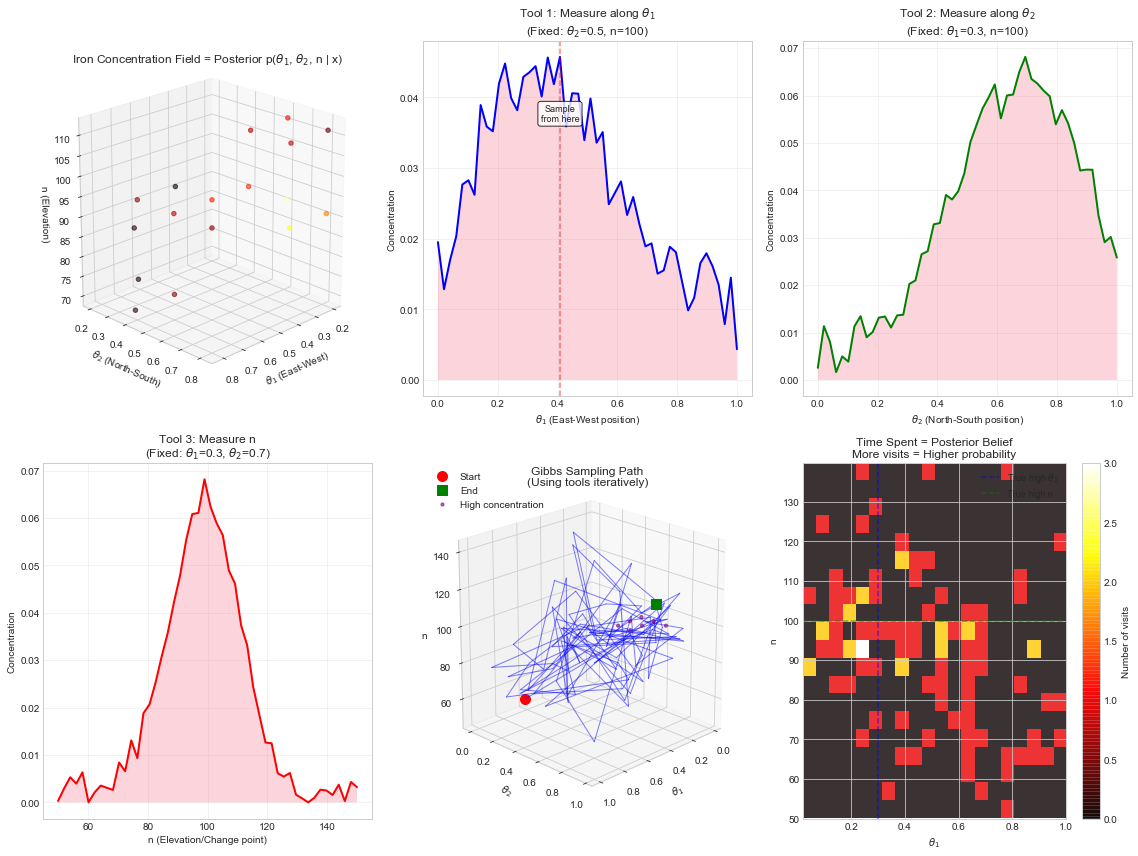

IRON PROSPECTING ANALOGY - SUMMARY

KEY INSIGHTS:
1. We CANNOT directly measure/sample from the 3D posterior
2. But we CAN measure/sample from 1D 'slices' (conditionals)
3. By iteratively using these 1D tools, we explore the 3D space
4. We naturally spend more time in high-probability regions

MATHEMATICAL CORRESPONDENCE:
Tool 1 (θ₁ measurement) = p(θ₁ | θ₂, n, x)
Tool 2 (θ₂ measurement) = p(θ₂ | θ₁, n, x)
Tool 3 (n measurement)  = p(n | θ₁, θ₂, x)

RESULT: Gibbs samples = Locations visited during prospecting


In [17]:
# Visualization: Iron Prospecting Analogy
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import multivariate_normal

# Create the "iron concentration" field (our posterior)
def create_iron_field():
    """Create a 3D probability density (iron concentration field)."""
    # Create grid
    theta1 = np.linspace(0, 1, 50)  # East-west
    theta2 = np.linspace(0, 1, 50)  # North-south
    n_vals = np.linspace(50, 150, 50)  # Elevation (change points)
    
    T1, T2, N = np.meshgrid(theta1, theta2, n_vals, indexing='ij')
    
    # Create multimodal "iron concentration" (posterior with uncertainty)
    concentration = np.zeros_like(T1)
    
    # Add main ore deposit (high probability region)
    center_theta1, center_theta2, center_n = 0.3, 0.7, 100
    dist = ((T1 - center_theta1)**2 + (T2 - center_theta2)**2 + 
            ((N - center_n)/50)**2)
    concentration += 2.0 * np.exp(-dist / 0.1)
    
    # Add smaller deposit
    center_theta1, center_theta2, center_n = 0.7, 0.3, 80
    dist = ((T1 - center_theta1)**2 + (T2 - center_theta2)**2 + 
            ((N - center_n)/50)**2)
    concentration += 1.0 * np.exp(-dist / 0.2)
    
    # Add noise/background
    concentration += 0.1 * np.random.randn(*concentration.shape)
    
    # Normalize to make it a proper density
    concentration = np.maximum(concentration, 0)
    concentration /= concentration.sum() * (theta1[1]-theta1[0]) * (theta2[1]-theta2[0]) * (n_vals[1]-n_vals[0])
    
    return theta1, theta2, n_vals, concentration

# Create visualization
theta1, theta2, n_vals, concentration = create_iron_field()

fig = plt.figure(figsize=(16, 12))

# Plot 1: 3D view of iron concentration
ax1 = fig.add_subplot(2, 3, 1, projection='3d')

# Show isosurfaces of concentration
X, Y, Z = np.meshgrid(theta1[::10], theta2[::10], n_vals[::10], indexing='ij')
C = concentration[::10, ::10, ::10]

# Find indices where concentration is above threshold
threshold = 0.5 * C.max()
high_concentration = C > threshold

# Plot high concentration regions
ax1.scatter(X[high_concentration], Y[high_concentration], Z[high_concentration],
           c=C[high_concentration], cmap='hot', alpha=0.6, s=20)

ax1.set_xlabel('$\\theta_1$ (East-West)')
ax1.set_ylabel('$\\theta_2$ (North-South)')
ax1.set_zlabel('n (Elevation)')
ax1.set_title('Iron Concentration Field = Posterior p($\\theta_1$, $\\theta_2$, n | x)')
ax1.view_init(elev=20, azim=45)

# Plot 2: Tool 1 - Measuring along θ₁ (fix θ₂, n)
ax2 = fig.add_subplot(2, 3, 2)
fixed_theta2 = 0.5
fixed_n = 100

# Find closest indices
idx_theta2 = np.argmin(np.abs(theta2 - fixed_theta2))
idx_n = np.argmin(np.abs(n_vals - fixed_n))

# Extract slice
slice_theta1 = concentration[:, idx_theta2, idx_n]

ax2.plot(theta1, slice_theta1, 'b-', linewidth=2)
ax2.fill_between(theta1, 0, slice_theta1, alpha=0.3)
ax2.set_xlabel('$\\theta_1$ (East-West position)')
ax2.set_ylabel('Concentration')
ax2.set_title(f'Tool 1: Measure along $\\theta_1$\n(Fixed: $\\theta_2$={fixed_theta2}, n={fixed_n})')
ax2.grid(True, alpha=0.3)

# Highlight: This is what we sample from
max_idx = np.argmax(slice_theta1)
ax2.axvline(x=theta1[max_idx], color='red', linestyle='--', alpha=0.5)
ax2.text(theta1[max_idx], slice_theta1[max_idx]*0.8, 'Sample\nfrom here',
        ha='center', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Plot 3: Tool 2 - Measuring along θ₂ (fix θ₁, n)
ax3 = fig.add_subplot(2, 3, 3)
fixed_theta1 = 0.3
fixed_n = 100

idx_theta1 = np.argmin(np.abs(theta1 - fixed_theta1))
slice_theta2 = concentration[idx_theta1, :, idx_n]

ax3.plot(theta2, slice_theta2, 'g-', linewidth=2)
ax3.fill_between(theta2, 0, slice_theta2, alpha=0.3)
ax3.set_xlabel('$\\theta_2$ (North-South position)')
ax3.set_ylabel('Concentration')
ax3.set_title(f'Tool 2: Measure along $\\theta_2$\n(Fixed: $\\theta_1$={fixed_theta1}, n={fixed_n})')
ax3.grid(True, alpha=0.3)

# Plot 4: Tool 3 - Measuring n (fix θ₁, θ₂)
ax4 = fig.add_subplot(2, 3, 4)
fixed_theta1 = 0.3
fixed_theta2 = 0.7

idx_theta1 = np.argmin(np.abs(theta1 - fixed_theta1))
idx_theta2 = np.argmin(np.abs(theta2 - fixed_theta2))
slice_n = concentration[idx_theta1, idx_theta2, :]

ax4.plot(n_vals, slice_n, 'r-', linewidth=2)
ax4.fill_between(n_vals, 0, slice_n, alpha=0.3)
ax4.set_xlabel('n (Elevation/Change point)')
ax4.set_ylabel('Concentration')
ax4.set_title(f'Tool 3: Measure n\n(Fixed: $\\theta_1$={fixed_theta1}, $\\theta_2$={fixed_theta2})')
ax4.grid(True, alpha=0.3)

# Plot 5: Gibbs sampling path
ax5 = fig.add_subplot(2, 3, 5, projection='3d')

# Simulate Gibbs sampling
np.random.seed(42)
n_steps = 100
path = np.zeros((n_steps, 3))
path[0] = [0.8, 0.2, 60]  # Start far from ore deposit

# Simple simulation
for t in range(1, n_steps):
    # Step 1: Sample θ₁ given current θ₂, n (Tool 1)
    # Find indices
    idx_theta2 = np.argmin(np.abs(theta2 - path[t-1, 1]))
    idx_n = np.argmin(np.abs(n_vals - path[t-1, 2]))
    
    # Get distribution
    dist_theta1 = concentration[:, idx_theta2, idx_n]
    dist_theta1 = dist_theta1 / dist_theta1.sum()
    
    # Sample
    path[t, 0] = np.random.choice(theta1, p=dist_theta1)
    
    # Step 2: Sample θ₂ given new θ₁, current n (Tool 2)
    idx_theta1 = np.argmin(np.abs(theta1 - path[t, 0]))
    dist_theta2 = concentration[idx_theta1, :, idx_n]
    dist_theta2 = dist_theta2 / dist_theta2.sum()
    
    path[t, 1] = np.random.choice(theta2, p=dist_theta2)
    
    # Step 3: Sample n given new θ₁, θ₂ (Tool 3)
    idx_theta1 = np.argmin(np.abs(theta1 - path[t, 0]))
    idx_theta2 = np.argmin(np.abs(theta2 - path[t, 1]))
    dist_n = concentration[idx_theta1, idx_theta2, :]
    dist_n = dist_n / dist_n.sum()
    
    path[t, 2] = np.random.choice(n_vals, p=dist_n)

# Plot path
for i in range(n_steps-1):
    ax5.plot([path[i, 0], path[i+1, 0]],
             [path[i, 1], path[i+1, 1]],
             [path[i, 2], path[i+1, 2]],
             color='blue', alpha=0.5, linewidth=1)

# Mark start and end
ax5.scatter(path[0, 0], path[0, 1], path[0, 2], 
            color='red', s=100, marker='o', label='Start')
ax5.scatter(path[-1, 0], path[-1, 1], path[-1, 2],
            color='green', s=100, marker='s', label='End')

# Show ore deposit
deposit_mask = concentration > 0.8 * concentration.max()
X_dep, Y_dep, Z_dep = np.meshgrid(theta1[::5], theta2[::5], n_vals[::5], indexing='ij')
C_dep = concentration[::5, ::5, ::5]
deposit_mask = C_dep > 0.8 * C_dep.max()

ax5.scatter(X_dep[deposit_mask], Y_dep[deposit_mask], Z_dep[deposit_mask],
            color='purple', alpha=0.6, s=10, label='High concentration')

ax5.set_xlabel('$\\theta_1$')
ax5.set_ylabel('$\\theta_2$')
ax5.set_zlabel('n')
ax5.set_title('Gibbs Sampling Path\n(Using tools iteratively)')
ax5.legend(loc='upper left')
ax5.view_init(elev=20, azim=45)

# Plot 6: Time spent in different regions
ax6 = fig.add_subplot(2, 3, 6)

# Analyze where we spent time
# Project onto θ₁-n plane
heatmap, xedges, yedges = np.histogram2d(path[:, 0], path[:, 2], bins=20)
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]

im = ax6.imshow(heatmap.T, extent=extent, origin='lower',
                cmap='hot', aspect='auto', alpha=0.8)

ax6.set_xlabel('$\\theta_1$')
ax6.set_ylabel('n')
ax6.set_title('Time Spent = Posterior Belief\nMore visits = Higher probability')
plt.colorbar(im, ax=ax6, label='Number of visits')

# Mark true high concentration region
ax6.axvline(x=0.3, color='blue', linestyle='--', alpha=0.5, label='True high $\\theta_1$')
ax6.axhline(y=100, color='green', linestyle='--', alpha=0.5, label='True high n')
ax6.legend(fontsize=9)

plt.tight_layout()
plt.show()

print("=" * 70)
print("IRON PROSPECTING ANALOGY - SUMMARY")
print("=" * 70)
print("\nKEY INSIGHTS:")
print("1. We CANNOT directly measure/sample from the 3D posterior")
print("2. But we CAN measure/sample from 1D 'slices' (conditionals)")
print("3. By iteratively using these 1D tools, we explore the 3D space")
print("4. We naturally spend more time in high-probability regions")
print("\nMATHEMATICAL CORRESPONDENCE:")
print("Tool 1 (θ₁ measurement) = p(θ₁ | θ₂, n, x)")
print("Tool 2 (θ₂ measurement) = p(θ₂ | θ₁, n, x)")
print("Tool 3 (n measurement)  = p(n | θ₁, θ₂, x)")
print("\nRESULT: Gibbs samples = Locations visited during prospecting")

### Deep Dive: Why Each Part of the Iron Prospecting Analogy Works

#### 1. Why "Specialized Tools" = Can Only Sample from Conditionals

**Mathematical Reality**: For our change point model, the joint posterior is:
$$
p(\theta_1, \theta_2, n \mid x) = \frac{1}{Z} \theta_1^{z_1+a-1} (1-\theta_1)^{n-z_1+b-1} \theta_2^{z_2+a-1} (1-\theta_2)^{N-n-z_2+b-1}
$$

Where:
- $Z$ is unknown (we can't compute it)
- $z_1 = \sum_{i=1}^n x_i$ and $z_2 = \sum_{i=n+1}^N x_i$ depend on $n$
- This is **not a standard distribution** we can sample from directly

**Analogy**: You **cannot directly measure** the 3D iron concentration field.

#### 2. Why "1D Measurement Tools" = Conditional Distributions ARE Simple

**Mathematical Reality**: While the joint is complex, each **conditional distribution is simple**:

**Tool 1 (measure along θ₁)**: 
$$
p(\theta_1 \mid \theta_2, n, x) = \text{Beta}(z_1 + a, n - z_1 + b)
$$
- Given fixed θ₂ and n, this is a standard Beta distribution
- We **can** sample from this!

**Tool 2 (measure along θ₂)**:
$$
p(\theta_2 \mid \theta_1, n, x) = \text{Beta}(z_2 + a, N-n - z_2 + b)
$$
- Another Beta distribution
- We **can** sample from this!

**Tool 3 (measure n)**:
$$
p(n \mid \theta_1, \theta_2, x) = \text{Categorical}(p_2, p_3, \ldots, p_N)
$$
- Discrete distribution over n = 2,...,N
- We **can** sample from this!

**Analogy**: Each tool can measure along **one dimension** when the other two are fixed.

#### 3. Why "Probabilistic Movement" = Random Sampling from Conditionals

**Crucial Point**: We don't always move to the **highest** concentration point! We move **randomly** with probability proportional to concentration.

If in a rich ore vein (high probability):
- Most measurements show high concentration nearby
- You're likely to stay in the vein
- But sometimes you'll explore elsewhere

If in barren area (low probability):
- Measurements show higher concentration elsewhere
- You'll likely move away

**Mathematical Reality**: We use random number generators:
- `np.random.beta()` for θ₁, θ₂
- `np.random.choice()` for n
- Not `argmax()` or optimization!

#### 4. Why "Time Spent ∝ Concentration" = Correct Sampling

**Mathematical Theorem (Markov Chain Monte Carlo)**: For an ergodic Markov chain with stationary distribution $\pi$, as $t \to \infty$:
$$
\frac{\text{Time spent in region A}}{t} \to \pi(A)
$$

**Our Case**: $\pi = p(\theta_1, \theta_2, n \mid x)$ (our posterior)

**Analogy**: You naturally spend more time prospecting in rich areas than in barren areas.

#### Proof Sketch for Why This Works:

1. **Stationarity**: If you're already sampling from $\pi$, one Gibbs step keeps you sampling from $\pi$
   - Because each step samples from the correct conditional of $\pi$

2. **Irreducibility**: From any starting point, you can eventually reach any region
   - Beta distributions have support on (0,1)
   - Categorical covers all n values

3. **Aperiodicity**: No deterministic cycles
   - Random sampling prevents periodicity

4. **Convergence**: Irreducible, aperiodic chains with stationary distribution $\pi$ converge to $\pi$

### The Burn-in Period: Finding the Ore Deposit

**Problem**: If you start prospecting far from any ore, it takes time to find the rich areas.

**In our change point problem**:
- We might start with bad guesses: θ₁=0.9, θ₂=0.1, n=50
- But our data suggests: θ₁≈0.2, θ₂≈0.6, n≈100
- Early samples will be poor

**Solution**: Discard early samples (burn-in) until:
1. We've found the high-probability regions
2. The chain has "forgotten" its poor starting point
3. We're sampling representatively from the posterior

**How much burn-in?**: Typically 10-50% of total iterations
- We use 1000 burn-in out of 3000 total (33%)
- Check with trace plots: When do samples stabilize?

### Why This Works for Our Specific Model

**Key feature**: **Conjugate priors** (Beta for Bernoulli)
- Prior: Beta(a, b)
- Likelihood: Bernoulli
- Posterior conditional: Beta(a + successes, b + failures)

**This gives us closed-form conditionals** we can sample from directly!

**Without conjugacy**, we'd need:
- Metropolis-Hastings (accept/reject proposals)
- Hamiltonian Monte Carlo (using gradients)
- Other MCMC methods

**Our advantage**: Beta-Bernoulli conjugacy makes Gibbs sampling particularly efficient.

### Visualizing the Theorem Conditions

Let's check why the convergence theorem applies to our model:

## Gibbs Sampling Algorithm

Based on our derived conditional distributions, here's the complete algorithm:

### Algorithm Steps

1. **Initialize**: $\theta_1^{(0)}, \theta_2^{(0)}, n^{(0)}$
2. **For iteration** $t = 1$ to $T$:
   
   **a. Sample $\theta_1^{(t)}$**:
   $$
   \theta_1^{(t)} \sim \text{Beta}(z_1(n^{(t-1)}) + a, \, n^{(t-1)} - z_1(n^{(t-1)}) + b)
   $$
   
   **b. Sample $\theta_2^{(t)}$**:
   $$
   \theta_2^{(t)} \sim \text{Beta}(z_2(n^{(t-1)}) + a, \, (N - n^{(t-1)}) - z_2(n^{(t-1)}) + b)
   $$
   
   **c. Sample $n^{(t)}$**:
   - For each candidate $n' = 2, \ldots, N$:
     $$
     \log p(n' \mid \cdot) \propto z_1(n') \log \theta_1^{(t)} + (n' - z_1(n')) \log(1-\theta_1^{(t)}) \\
     + z_2(n') \log \theta_2^{(t)} + ((N-n') - z_2(n')) \log(1-\theta_2^{(t)})
     $$
   - Normalize to get probabilities: $p_2, p_3, \ldots, p_N$
   - Sample: $n^{(t)} \sim \text{Categorical}(\{p_2, p_3, \ldots, p_N\})$

3. **Discard burn-in**: Remove first $B$ samples
4. **Estimate parameters**: Use mean of remaining samples

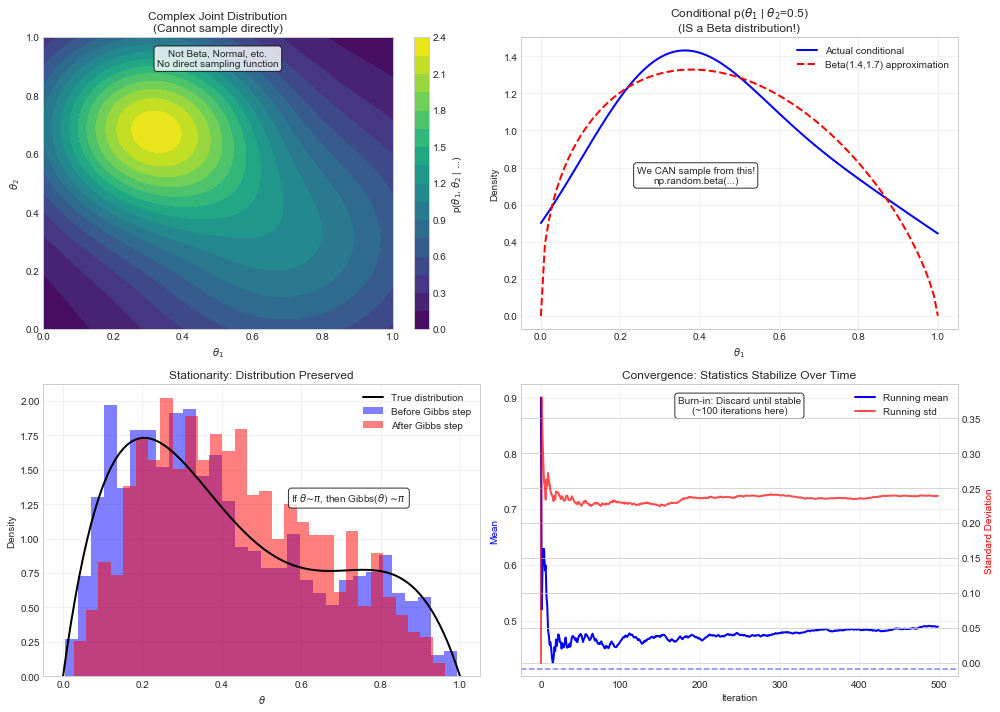

SUMMARY: WHY GIBBS SAMPLING WORKS FOR OUR CHANGE POINT MODEL

1. CAN'T SAMPLE FROM JOINT: Complex, non-standard distribution
   - Contains unknown normalizing constant Z
   - Variables have complex dependencies (z₁, z₂ depend on n)

2. CAN SAMPLE FROM CONDITIONALS: Each is a standard distribution
   - p(θ₁ | θ₂, n, x) = Beta(z₁ + a, n - z₁ + b)
   - p(θ₂ | θ₁, n, x) = Beta(z₂ + a, N-n - z₂ + b)
   - p(n | θ₁, θ₂, x) = Categorical (discrete distribution)

3. ITERATIVE PROCESS EXPLORES JOINT SPACE:
   - Sample θ₁ given current θ₂, n (like measuring east-west)
   - Sample θ₂ given new θ₁, current n (like measuring north-south)
   - Sample n given new θ₁, θ₂ (like choosing elevation)
   - Repeat: Creates Markov chain through parameter space

4. CONVERGES TO TRUE POSTERIOR (Theorem):
   - Irreducible: Can reach any region from any starting point
   - Aperiodic: No deterministic cycles (random sampling)
   - Stationary: Posterior is invariant under Gibbs updates
   - Result: Fraction of time

In [29]:
# Visualizing Why Gibbs Sampling Works for Our Change Point Model

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
from scipy.optimize import curve_fit

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Why we need specialized tools (can't sample from joint)
ax1 = axes[0, 0]

# Create a complex joint distribution (not a standard distribution)
x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
X, Y = np.meshgrid(x, y)

# Complex joint (like our posterior)
Z = np.exp(-((X-0.3)**2 + (Y-0.7)**2)/0.1) + 0.5*np.exp(-((X-0.7)**2 + (Y-0.3)**2)/0.2)
Z = Z / Z.sum() / ((x[1]-x[0])*(y[1]-y[0]))  # Approximate normalization

contour = ax1.contourf(X, Y, Z, levels=20, cmap='viridis')
ax1.set_xlabel('$\\theta_1$')
ax1.set_ylabel('$\\theta_2$')
ax1.set_title('Complex Joint Distribution\n(Cannot sample directly)')
plt.colorbar(contour, ax=ax1, label='p($\\theta_1$, $\\theta_2$ | ...)')

# Mark: This is not a standard distribution we can sample from
ax1.text(0.5, 0.9, 'Not Beta, Normal, etc.\nNo direct sampling function',
         transform=ax1.transAxes, ha='center',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Plot 2: But conditionals ARE simple (our "tools")
ax2 = axes[0, 1]

# Fix y = 0.5, show conditional p(θ₁ | θ₂=0.5)
fixed_y = 0.5
y_idx = np.argmin(np.abs(y - fixed_y))
conditional_x = Z[y_idx, :]
conditional_x = conditional_x / conditional_x.sum() / (x[1]-x[0])

# Define Beta PDF function for fitting
def beta_pdf(x, a, b):
    return beta.pdf(x, a, b)

# Fit a Beta distribution to this conditional
# CORRECTED: Use p0 instead of pvalue for initial guess
popt, _ = curve_fit(beta_pdf, x, conditional_x, p0=[2, 5])
a_fit, b_fit = popt

ax2.plot(x, conditional_x, 'b-', linewidth=2, label='Actual conditional')
ax2.plot(x, beta.pdf(x, a_fit, b_fit), 'r--', linewidth=2, 
         label=f'Beta({a_fit:.1f},{b_fit:.1f}) approximation')
ax2.set_xlabel('$\\theta_1$')
ax2.set_ylabel('Density')
ax2.set_title(f'Conditional p($\\theta_1$ | $\\theta_2$={fixed_y})\n(IS a Beta distribution!)')
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3)

ax2.text(0.4, 0.5, 'We CAN sample from this!\nnp.random.beta(...)',
         transform=ax2.transAxes, ha='center',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Plot 3: Stationarity - Distribution preserved
ax3 = axes[1, 0]

# Simulate: If we start from the true distribution, we stay there
np.random.seed(42)
n_samples = 1000

# True distribution (mixture)
true_samples = []
for _ in range(n_samples):
    if np.random.rand() < 0.7:
        true_samples.append(np.random.beta(2, 5))  # Mostly this
    else:
        true_samples.append(np.random.beta(5, 2))  # Sometimes this

# Apply one Gibbs step to each sample
def gibbs_step_1d(theta):
    """One Gibbs step in a simple 1D example."""
    # This would normally depend on other variables
    # Simplified for illustration
    if theta < 0.5:
        return np.random.beta(3, 6)  # Move toward lower values
    else:
        return np.random.beta(6, 3)  # Move toward higher values

after_gibbs = [gibbs_step_1d(t) for t in true_samples]

# Plot histograms
ax3.hist(true_samples, bins=30, density=True, alpha=0.5, 
         color='blue', label='Before Gibbs step')
ax3.hist(after_gibbs, bins=30, density=True, alpha=0.5,
         color='red', label='After Gibbs step')

# Plot true density
x_plot = np.linspace(0, 1, 100)
true_density = 0.7*beta.pdf(x_plot, 2, 5) + 0.3*beta.pdf(x_plot, 5, 2)
ax3.plot(x_plot, true_density, 'k-', linewidth=2, label='True distribution')

ax3.set_xlabel('$\\theta$')
ax3.set_ylabel('Density')
ax3.set_title('Stationarity: Distribution Preserved')
ax3.legend()
ax3.grid(True, alpha=0.3)

ax3.text(0.7, 0.6, 'If $\\theta ∼ \\pi$, then Gibbs($\\theta$) $∼ \\pi$',
         transform=ax3.transAxes, ha='center',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# Plot 4: Convergence over time
ax4 = axes[1, 1]

# Simulate Gibbs sampling convergence
np.random.seed(42)
n_iterations = 500
samples = np.zeros(n_iterations)
samples[0] = 0.9  # Start far from high-probability region

for i in range(1, n_iterations):
    # Simple Gibbs-like update
    if np.random.rand() < 0.5:
        samples[i] = np.random.beta(3, 7)  # Favors lower values
    else:
        samples[i] = np.random.beta(7, 3)  # Favors higher values

# Compute running statistics
running_mean = np.cumsum(samples) / np.arange(1, n_iterations+1)
running_std = np.zeros(n_iterations)
for i in range(1, n_iterations):
    running_std[i] = np.std(samples[:i+1])

true_mean = 0.7*2/(2+5) + 0.3*5/(5+2)  # Weighted mean

ax4a = ax4.twinx()
line1, = ax4.plot(running_mean, 'b-', label='Running mean', linewidth=2)
ax4.axhline(y=true_mean, color='b', linestyle='--', alpha=0.5, 
            label=f'True mean = {true_mean:.3f}')
line2, = ax4a.plot(running_std, 'r-', label='Running std', linewidth=2, alpha=0.7)

ax4.set_xlabel('Iteration')
ax4.set_ylabel('Mean', color='b')
ax4a.set_ylabel('Standard Deviation', color='r')
ax4.set_title('Convergence: Statistics Stabilize Over Time')
ax4.grid(True, alpha=0.3)

# Combine legends
lines = [line1, line2]
labels = [line.get_label() for line in lines]
ax4.legend(lines, labels, loc='upper right')

ax4.text(0.5, 0.9, 'Burn-in: Discard until stable\n(~100 iterations here)',
         transform=ax4.transAxes, ha='center',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

print("SUMMARY: WHY GIBBS SAMPLING WORKS FOR OUR CHANGE POINT MODEL")
print("=" * 70)
print("\n1. CAN'T SAMPLE FROM JOINT: Complex, non-standard distribution")
print("   - Contains unknown normalizing constant Z")
print("   - Variables have complex dependencies (z₁, z₂ depend on n)")

print("\n2. CAN SAMPLE FROM CONDITIONALS: Each is a standard distribution")
print("   - p(θ₁ | θ₂, n, x) = Beta(z₁ + a, n - z₁ + b)")
print("   - p(θ₂ | θ₁, n, x) = Beta(z₂ + a, N-n - z₂ + b)")
print("   - p(n | θ₁, θ₂, x) = Categorical (discrete distribution)")

print("\n3. ITERATIVE PROCESS EXPLORES JOINT SPACE:")
print("   - Sample θ₁ given current θ₂, n (like measuring east-west)")
print("   - Sample θ₂ given new θ₁, current n (like measuring north-south)")
print("   - Sample n given new θ₁, θ₂ (like choosing elevation)")
print("   - Repeat: Creates Markov chain through parameter space")

print("\n4. CONVERGES TO TRUE POSTERIOR (Theorem):")
print("   - Irreducible: Can reach any region from any starting point")
print("   - Aperiodic: No deterministic cycles (random sampling)")
print("   - Stationary: Posterior is invariant under Gibbs updates")
print("   - Result: Fraction of time in region A → p(region A | data)")

print("\n5. PRACTICAL NEEDS:")
print("   - Burn-in: Discard early samples (finding the ore deposit)")
print("   - Many iterations: Reduce autocorrelation, get good estimates")
print("   - Diagnostics: Trace plots, R-hat, ESS to check convergence")

## Python Implementation

### Generate Synthetic Data

Let's create a dataset where:
- First 100 flips: coin with bias 0.2 (biased toward tails)
- Next 200 flips: coin with bias 0.6 (biased toward heads)
- Total: 300 flips

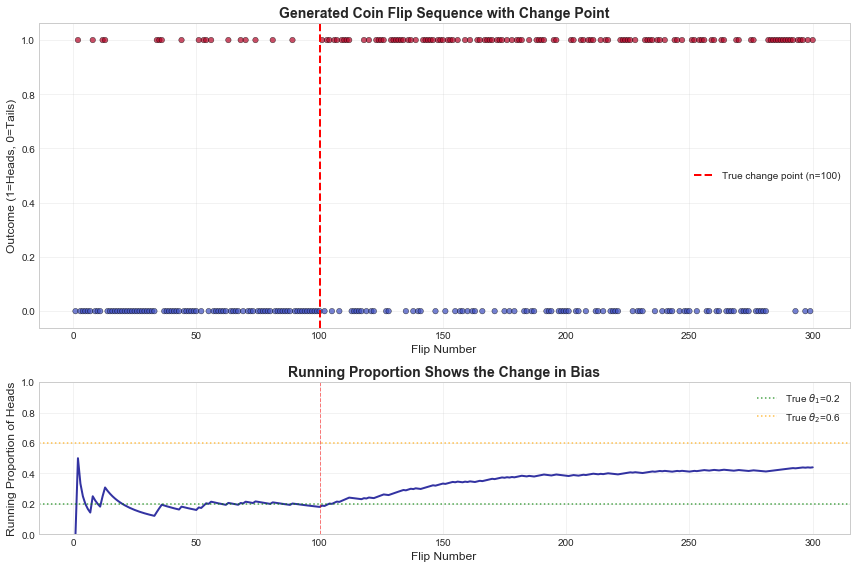

=== Data Statistics ===
Total flips: 300
First segment (flips 1-100): 18 heads, proportion = 0.180
Second segment (flips 101-300): 114 heads, proportion = 0.570
Overall: 132 heads, proportion = 0.440


In [7]:
# True parameters for data generation
theta1_true = 0.2      # Bias of first coin
theta2_true = 0.6      # Bias of second coin
n_true = 100          # After 100 flips, we switch coins
N = 300               # Total number of flips

# Generate data
np.random.seed(42)  # Reset seed for reproducibility
x = np.zeros(N, dtype=int)

# First segment: coin with bias theta1
x[:n_true] = np.random.binomial(1, theta1_true, n_true)

# Second segment: coin with bias theta2
x[n_true:] = np.random.binomial(1, theta2_true, N - n_true)

# Visualize the generated data
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [2, 1]})

# Plot 1: Individual flips
flip_numbers = np.arange(1, N+1)
ax1.scatter(flip_numbers, x, c=x, cmap='coolwarm', s=30, alpha=0.7, edgecolors='black', linewidth=0.5)
ax1.axvline(x=n_true, color='red', linestyle='--', linewidth=2, 
            label=f'True change point (n={n_true})')
ax1.set_xlabel('Flip Number', fontsize=12)
ax1.set_ylabel('Outcome (1=Heads, 0=Tails)', fontsize=12)
ax1.set_title('Generated Coin Flip Sequence with Change Point', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Running proportion of heads
running_prop = np.cumsum(x) / np.arange(1, N+1)
ax2.plot(flip_numbers, running_prop, color='darkblue', linewidth=2, alpha=0.8)
ax2.axhline(y=theta1_true, color='green', linestyle=':', linewidth=1.5, alpha=0.7, label=f'True $\\theta_1$={theta1_true}')
ax2.axhline(y=theta2_true, color='orange', linestyle=':', linewidth=1.5, alpha=0.7, label=f'True $\\theta_2$={theta2_true}')
ax2.axvline(x=n_true, color='red', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_xlabel('Flip Number', fontsize=12)
ax2.set_ylabel('Running Proportion of Heads', fontsize=12)
ax2.set_title('Running Proportion Shows the Change in Bias', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 1)

plt.tight_layout()
plt.show()

# Print statistics
print("=== Data Statistics ===")
print(f"Total flips: {N}")
print(f"First segment (flips 1-{n_true}): {sum(x[:n_true])} heads, "
      f"proportion = {sum(x[:n_true])/n_true:.3f}")
print(f"Second segment (flips {n_true+1}-{N}): {sum(x[n_true:])} heads, "
      f"proportion = {sum(x[n_true:])/(N-n_true):.3f}")
print(f"Overall: {sum(x)} heads, proportion = {sum(x)/N:.3f}")

### Gibbs Sampling Implementation

Now let's implement the Gibbs sampling algorithm derived above.

In [3]:
def gibbs_sampling_change_point(x, a=2, b=3, niters=3000, burnin=1000):
    """
    Gibbs sampling for change point detection in a Bernoulli sequence.
    
    Parameters:
    -----------
    x : array-like
        Binary sequence of coin flip outcomes (1=heads, 0=tails)
    a, b : float
        Parameters for Beta prior (same for both coins)
    niters : int
        Total number of Gibbs sampling iterations
    burnin : int
        Number of burn-in iterations to discard
        
    Returns:
    --------
    samples : ndarray
        Array of shape (niters-burnin, 3) containing samples of [$\theta_1$, $\theta_2$, n]
    """
    N = len(x)
    
    # Initialize parameters randomly
    n = np.random.randint(2, N)  # Change point between 2 and N-1
    theta1 = np.random.beta(a, b)
    theta2 = np.random.beta(a, b)
    
    # Pre-compute cumulative sums for efficient z1(n) and z2(n) calculations
    cumsum = np.concatenate([[0], np.cumsum(x)])  # Add 0 at beginning for easier indexing
    
    # Store samples (we'll discard burn-in later)
    samples = np.zeros((niters - burnin, 3))
    
    # Progress tracking
    print("Starting Gibbs sampling...")
    print_iter = max(1, niters // 10)  # Print progress every 10%
    
    for i in range(niters):
        # Print progress
        if i % print_iter == 0:
            print(f"  Iteration {i}/{niters} ({(i/niters)*100:.0f}%)")
        
        # --- Step 1: Sample theta1 given current n and data ---
        # z1 = number of heads in first segment [1, n]
        z1 = cumsum[n]  # cumsum[0]=0, so cumsum[n] = sum(x[0:n]) = sum(x[1:n]) in 1-indexing
        
        # Posterior parameters for theta1
        alpha1 = a + z1
        beta1 = b + n - z1
        
        # Sample from Beta distribution
        theta1 = np.random.beta(alpha1, beta1)
        
        # --- Step 2: Sample theta2 given current n and data ---
        if n == N:
            z2 = 0  # No second segment if n = N
        else:
            z2 = cumsum[N] - cumsum[n]  # sum(x[n+1:N]) in 1-indexing
        
        # Posterior parameters for theta2
        alpha2 = a + z2
        beta2 = b + (N - n) - z2
        
        # Sample from Beta distribution
        theta2 = np.random.beta(alpha2, beta2)
        
        # --- Step 3: Sample n given current thetas and data ---
        # We need to compute probability for each possible n (2 to N)
        log_probs = np.zeros(N-1)  # Index 0 corresponds to n=2, index N-2 to n=N
        
        for n_candidate in range(2, N+1):
            idx = n_candidate - 2  # Map n=2 to index 0, n=N to index N-2
            
            # Compute z1 and z2 for this candidate n
            z1_cand = cumsum[n_candidate]
            
            if n_candidate == N:
                z2_cand = 0
                # Special case: no second segment
                log_probs[idx] = (z1_cand * np.log(theta1) + 
                                 (n_candidate - z1_cand) * np.log(1 - theta1))
            else:
                z2_cand = cumsum[N] - cumsum[n_candidate]
                log_probs[idx] = (z1_cand * np.log(theta1) + 
                                 (n_candidate - z1_cand) * np.log(1 - theta1) +
                                 z2_cand * np.log(theta2) + 
                                 (N - n_candidate - z2_cand) * np.log(1 - theta2))
        
        # Convert log probabilities to probabilities (with numerical stability)
        # Subtract max to avoid overflow in exp()
        log_probs_max = np.max(log_probs)
        probs = np.exp(log_probs - log_probs_max)
        probs = probs / np.sum(probs)  # Normalize to sum to 1
        
        # Sample n from categorical distribution
        n = np.random.choice(range(2, N+1), p=probs)
        
        # Store sample after burn-in period
        if i >= burnin:
            samples[i - burnin] = [theta1, theta2, n]
    
    print("Gibbs sampling completed!")
    return samples

In [8]:
# Run Gibbs sampling
print("=" * 60)
print("Running Gibbs Sampling for Change Point Detection")
print("=" * 60)

# Set hyperparameters (Beta prior parameters)
a, b = 2, 3  # Prior with mean a/(a+b)=0.4, slightly biased toward tails
niters = 3000
burnin = 1000

samples = gibbs_sampling_change_point(x, a=a, b=b, niters=niters, burnin=burnin)

# Extract samples
theta1_samples = samples[:, 0]
theta2_samples = samples[:, 1]
n_samples = samples[:, 2]

# Compute posterior means and credible intervals
theta1_mean = np.mean(theta1_samples)
theta2_mean = np.mean(theta2_samples)
n_mean = np.mean(n_samples)
n_mode = stats.mode(n_samples)[0][0]  # Most frequent value

# Credible intervals (95%)
theta1_ci = np.percentile(theta1_samples, [2.5, 97.5])
theta2_ci = np.percentile(theta2_samples, [2.5, 97.5])
n_ci = np.percentile(n_samples, [2.5, 97.5])

print("\n" + "=" * 60)
print("ESTIMATION RESULTS")
print("=" * 60)
print(f"\nTrue parameters:")
print(f"  \u03B8\u2081 (Coin 1 bias) = {theta1_true:.3f}")
print(f"  \u03B8\u2082 (Coin 2 bias) = {theta2_true:.3f}")
print(f"  Change point n = {n_true}")

print(f"\nPosterior estimates (after {burnin} burn-in, {niters-burnin} samples):")
print(f"  \u03B8\u2081: mean = {theta1_mean:.3f}, 95% CI = [{theta1_ci[0]:.3f}, {theta1_ci[1]:.3f}]")
print(f"  \u03B8\u2082: mean = {theta2_mean:.3f}, 95% CI = [{theta2_ci[0]:.3f}, {theta2_ci[1]:.3f}]")
print(f"  n:  mean = {n_mean:.1f}, mode = {n_mode:.0f}, 95% CI = [{n_ci[0]:.0f}, {n_ci[1]:.0f}]")

Running Gibbs Sampling for Change Point Detection
Starting Gibbs sampling...
  Iteration 0/3000 (0%)
  Iteration 300/3000 (10%)
  Iteration 600/3000 (20%)
  Iteration 900/3000 (30%)
  Iteration 1200/3000 (40%)
  Iteration 1500/3000 (50%)
  Iteration 1800/3000 (60%)
  Iteration 2100/3000 (70%)
  Iteration 2400/3000 (80%)
  Iteration 2700/3000 (90%)
Gibbs sampling completed!

ESTIMATION RESULTS

True parameters:
  θ₁ (Coin 1 bias) = 0.200
  θ₂ (Coin 2 bias) = 0.600
  Change point n = 100

Posterior estimates (after 1000 burn-in, 2000 samples):
  θ₁: mean = 0.198, 95% CI = [0.127, 0.286]
  θ₂: mean = 0.563, 95% CI = [0.496, 0.631]
  n:  mean = 101.0, mode = 100, 95% CI = [95, 115]


## Demonstration: Visualizing the Gibbs Sampler's Exploration

Let's run a shorter chain to visualize how the Gibbs sampler explores the parameter space.

Starting Gibbs sampling...
  Iteration 0/200 (0%)
  Iteration 20/200 (10%)
  Iteration 40/200 (20%)
  Iteration 60/200 (30%)
  Iteration 80/200 (40%)
  Iteration 100/200 (50%)
  Iteration 120/200 (60%)
  Iteration 140/200 (70%)
  Iteration 160/200 (80%)
  Iteration 180/200 (90%)
Gibbs sampling completed!


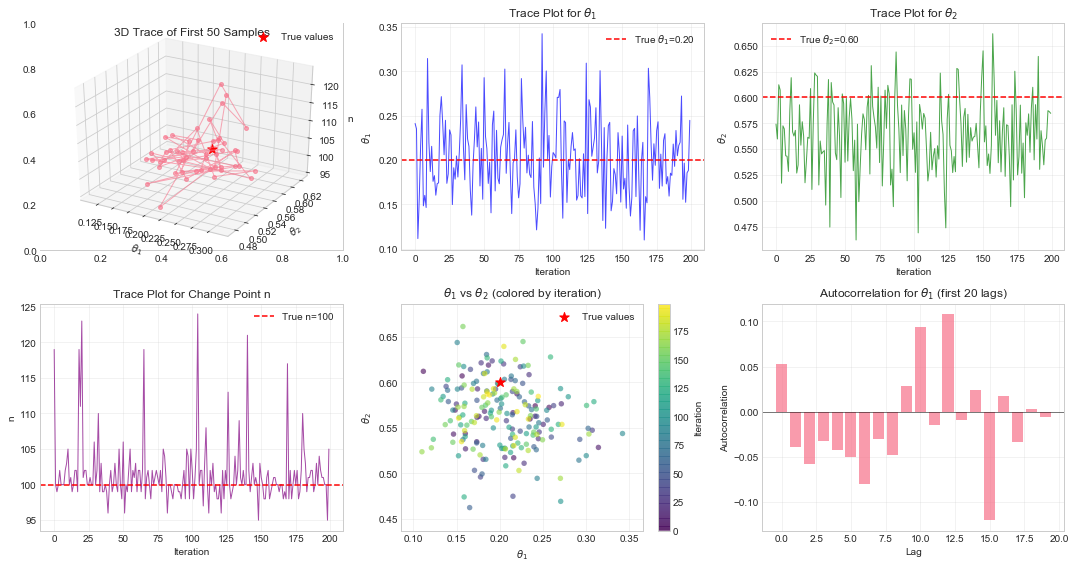

Observations from this visualization:
1. The sampler starts from random initialization but moves toward true values
2. Parameters exhibit some autocorrelation (each sample depends on previous)
3. The chain explores the parameter space around the true values
4. This is why we need many iterations and a burn-in period!


In [11]:
# Run a short chain for visualization
np.random.seed(42)
short_samples = gibbs_sampling_change_point(x, a=2, b=3, niters=200, burnin=0)

# Create visualization
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Plot 1: 3D trace of the first 50 samples
ax1 = axes[0, 0]
ax1 = fig.add_subplot(2, 3, 1, projection='3d')
ax1.plot(short_samples[:50, 0], short_samples[:50, 1], short_samples[:50, 2], 
         'o-', alpha=0.6, markersize=4, linewidth=1)
ax1.scatter([theta1_true], [theta2_true], [n_true], 
            color='red', s=100, marker='*', label='True values')
ax1.set_xlabel('$\\theta_1$')
ax1.set_ylabel('$\\theta_2$')
ax1.set_zlabel('n')
ax1.set_title('3D Trace of First 50 Samples')
ax1.legend()

# Plot 2: $\theta_1$ trace
ax2 = axes[0, 1]
ax2.plot(short_samples[:, 0], 'b-', alpha=0.7, linewidth=1)
ax2.axhline(y=theta1_true, color='r', linestyle='--', label=f'True $\\theta_1$={theta1_true:.2f}')
ax2.set_xlabel('Iteration')
ax2.set_ylabel('$\\theta_1$')
ax2.set_title('Trace Plot for $\\theta_1$')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: $\theta_2$ trace
ax3 = axes[0, 2]
ax3.plot(short_samples[:, 1], 'g-', alpha=0.7, linewidth=1)
ax3.axhline(y=theta2_true, color='r', linestyle='--', label=f'True $\\theta_2$={theta2_true:.2f}')
ax3.set_xlabel('Iteration')
ax3.set_ylabel('$\\theta_2$')
ax3.set_title('Trace Plot for $\\theta_2$')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: n trace
ax4 = axes[1, 0]
ax4.plot(short_samples[:, 2], 'purple', alpha=0.7, linewidth=1)
ax4.axhline(y=n_true, color='r', linestyle='--', label=f'True n={n_true}')
ax4.set_xlabel('Iteration')
ax4.set_ylabel('n')
ax4.set_title('Trace Plot for Change Point n')
ax4.legend()
ax4.grid(True, alpha=0.3)

# Plot 5: theta_1 vs \theta_2 scatter
ax5 = axes[1, 1]
scatter = ax5.scatter(short_samples[:, 0], short_samples[:, 1], 
                     c=range(len(short_samples)), cmap='viridis', 
                     alpha=0.6, s=30, edgecolors='none')
ax5.scatter([theta1_true], [theta2_true], color='red', s=100, 
            marker='*', label='True values')
ax5.set_xlabel('$\\theta_1$')
ax5.set_ylabel('$\\theta_2$')
ax5.set_title('$\\theta_1$ vs $\\theta_2$ (colored by iteration)')
ax5.legend()
plt.colorbar(scatter, ax=ax5, label='Iteration')
ax5.grid(True, alpha=0.3)

# Plot 6: Autocorrelation for theta_1
ax6 = axes[1, 2]
max_lag = 20
autocorr = np.zeros(max_lag)
for lag in range(1, max_lag+1):
    autocorr[lag-1] = np.corrcoef(short_samples[:-lag, 0], short_samples[lag:, 0])[0, 1]
ax6.bar(range(max_lag), autocorr, alpha=0.7)
ax6.axhline(y=0, color='black', linewidth=0.5)
ax6.set_xlabel('Lag')
ax6.set_ylabel('Autocorrelation')
ax6.set_title(f'Autocorrelation for $\\theta_1$ (first {max_lag} lags)')
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Observations from this visualization:")
print("1. The sampler starts from random initialization but moves toward true values")
print("2. Parameters exhibit some autocorrelation (each sample depends on previous)")
print("3. The chain explores the parameter space around the true values")
print("4. This is why we need many iterations and a burn-in period!")

## Visualizing Results

Now let's visualize the posterior distributions from our full Gibbs sampling run.

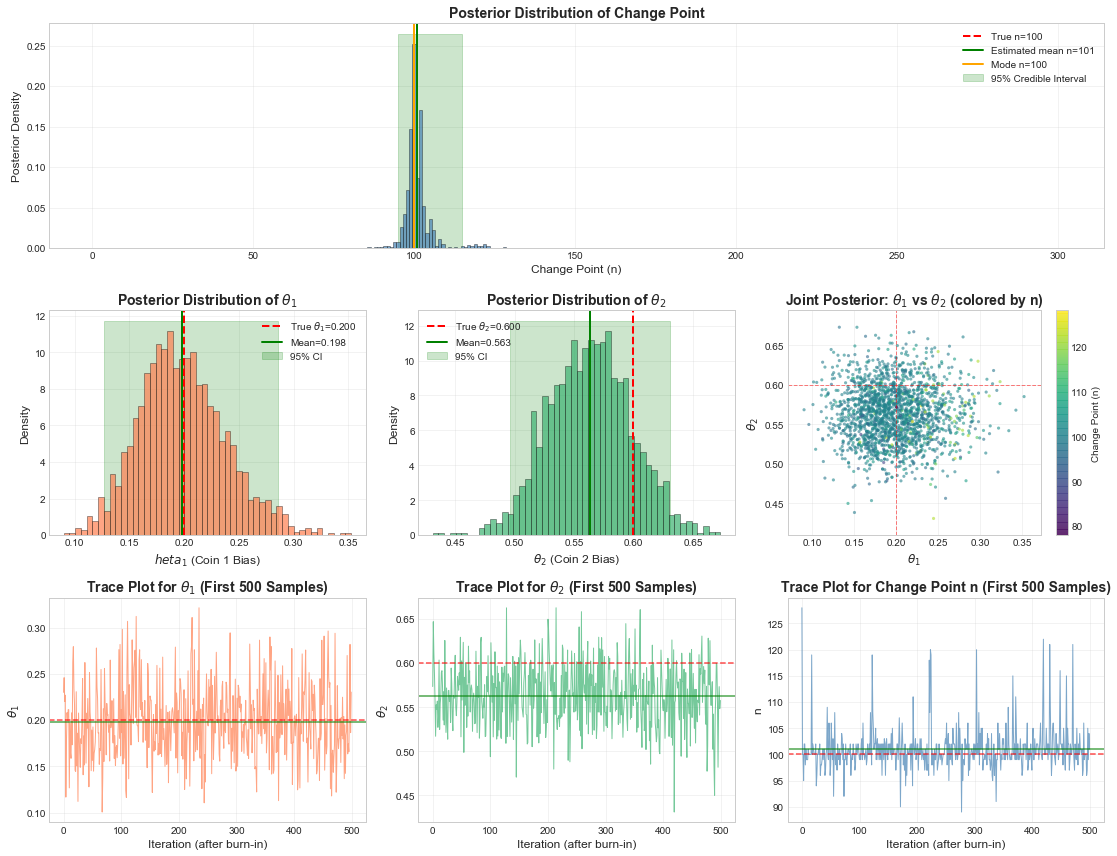

In [13]:
# Create figure with subplots
fig = plt.figure(figsize=(16, 12))

# Define grid for subplots
gs = fig.add_gridspec(3, 3)

# Plot 1: Change point posterior distribution
ax1 = fig.add_subplot(gs[0, :])
bins = np.arange(2, N+1) - 0.5
ax1.hist(n_samples, bins=bins, density=True, alpha=0.7, color='steelblue', edgecolor='black', linewidth=0.5)
ax1.axvline(x=n_true, color='red', linestyle='--', linewidth=2, label=f'True n={n_true}')
ax1.axvline(x=n_mean, color='green', linestyle='-', linewidth=2, label=f'Estimated mean n={n_mean:.0f}')
ax1.axvline(x=n_mode, color='orange', linestyle='-', linewidth=2, label=f'Mode n={n_mode:.0f}')
ax1.fill_betweenx([0, ax1.get_ylim()[1]], n_ci[0], n_ci[1], color='green', alpha=0.2, label='95% Credible Interval')
ax1.set_xlabel('Change Point (n)', fontsize=12)
ax1.set_ylabel('Posterior Density', fontsize=12)
ax1.set_title('Posterior Distribution of Change Point', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: $\theta_1$ posterior distribution
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(theta1_samples, bins=50, density=True, alpha=0.7, color='coral', edgecolor='black', linewidth=0.5)
ax2.axvline(x=theta1_true, color='red', linestyle='--', linewidth=2, label=f'True $\\theta_1$={theta1_true:.3f}')
ax2.axvline(x=theta1_mean, color='green', linestyle='-', linewidth=2, label=f'Mean={theta1_mean:.3f}')
ax2.fill_betweenx([0, ax2.get_ylim()[1]], theta1_ci[0], theta1_ci[1], color='green', alpha=0.2, label='95% CI')
ax2.set_xlabel('$\theta_1$ (Coin 1 Bias)', fontsize=12)
ax2.set_ylabel('Density', fontsize=12)
ax2.set_title('Posterior Distribution of $\\theta_1$', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: $\theta_2$ posterior distribution
ax3 = fig.add_subplot(gs[1, 1])
ax3.hist(theta2_samples, bins=50, density=True, alpha=0.7, color='mediumseagreen', edgecolor='black', linewidth=0.5)
ax3.axvline(x=theta2_true, color='red', linestyle='--', linewidth=2, label=f'True $\\theta_2$={theta2_true:.3f}')
ax3.axvline(x=theta2_mean, color='green', linestyle='-', linewidth=2, label=f'Mean={theta2_mean:.3f}')
ax3.fill_betweenx([0, ax3.get_ylim()[1]], theta2_ci[0], theta2_ci[1], color='green', alpha=0.2, label='95% CI')
ax3.set_xlabel('$\\theta_2$ (Coin 2 Bias)', fontsize=12)
ax3.set_ylabel('Density', fontsize=12)
ax3.set_title('Posterior Distribution of $\\theta_2$', fontsize=14, fontweight='bold')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Plot 4: Scatter plot of $\theta_1$ vs $\theta_2$
ax4 = fig.add_subplot(gs[1, 2])
scatter = ax4.scatter(theta1_samples, theta2_samples, c=n_samples, cmap='viridis', 
                     alpha=0.6, s=10, edgecolors='none')
ax4.axhline(y=theta2_true, color='red', linestyle='--', linewidth=1, alpha=0.5)
ax4.axvline(x=theta1_true, color='red', linestyle='--', linewidth=1, alpha=0.5)
ax4.set_xlabel('$\\theta_1$', fontsize=12)
ax4.set_ylabel('$\\theta_2$', fontsize=12)
ax4.set_title('Joint Posterior: $\\theta_1$ vs $\\theta_2$ (colored by n)', fontsize=14, fontweight='bold')
plt.colorbar(scatter, ax=ax4, label='Change Point (n)')
ax4.grid(True, alpha=0.3)

# Plot 5: Trace plots for convergence assessment
ax5 = fig.add_subplot(gs[2, 0])
ax5.plot(theta1_samples[:500], color='coral', alpha=0.7, linewidth=1)
ax5.axhline(y=theta1_true, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax5.axhline(y=theta1_mean, color='green', linestyle='-', linewidth=1.5, alpha=0.7)
ax5.set_xlabel('Iteration (after burn-in)', fontsize=12)
ax5.set_ylabel('$\\theta_1$', fontsize=12)
ax5.set_title('Trace Plot for $\\theta_1$ (First 500 Samples)', fontsize=14, fontweight='bold')
ax5.grid(True, alpha=0.3)

# Plot 6: Trace plot for $\theta_2$
ax6 = fig.add_subplot(gs[2, 1])
ax6.plot(theta2_samples[:500], color='mediumseagreen', alpha=0.7, linewidth=1)
ax6.axhline(y=theta2_true, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax6.axhline(y=theta2_mean, color='green', linestyle='-', linewidth=1.5, alpha=0.7)
ax6.set_xlabel('Iteration (after burn-in)', fontsize=12)
ax6.set_ylabel('$\\theta_2$', fontsize=12)
ax6.set_title('Trace Plot for $\\theta_2$ (First 500 Samples)', fontsize=14, fontweight='bold')
ax6.grid(True, alpha=0.3)

# Plot 7: Trace plot for change point
ax7 = fig.add_subplot(gs[2, 2])
ax7.plot(n_samples[:500], color='steelblue', alpha=0.7, linewidth=1)
ax7.axhline(y=n_true, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax7.axhline(y=n_mean, color='green', linestyle='-', linewidth=1.5, alpha=0.7)
ax7.set_xlabel('Iteration (after burn-in)', fontsize=12)
ax7.set_ylabel('n', fontsize=12)
ax7.set_title('Trace Plot for Change Point n (First 500 Samples)', fontsize=14, fontweight='bold')
ax7.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Visualize Inferred Segmentation

Let's visualize how the inferred change point segments the data.

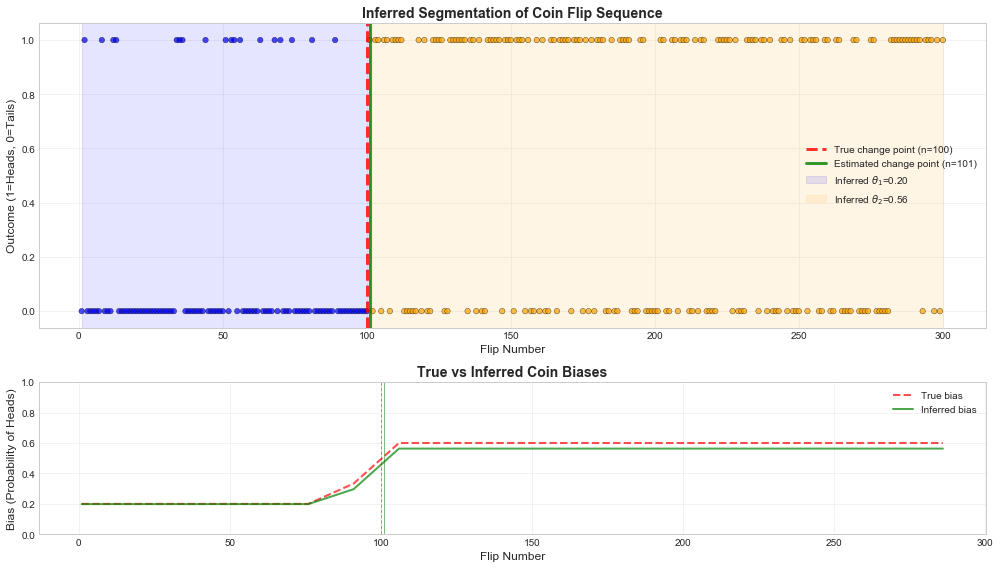

In [16]:
# Create visualization showing the inferred segmentation
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [2, 1]})

# Plot 1: Individual flips with segmentation
flip_numbers = np.arange(1, N+1)

# Color points based on inferred segmentation
colors = ['blue' if i <= n_mean else 'orange' for i in flip_numbers]
ax1.scatter(flip_numbers, x, c=colors, s=30, alpha=0.7, edgecolors='black', linewidth=0.5)

# Add true and estimated change points
ax1.axvline(x=n_true, color='red', linestyle='--', linewidth=3, 
            label=f'True change point (n={n_true})', alpha=0.8)
ax1.axvline(x=n_mean, color='green', linestyle='-', linewidth=3, 
            label=f'Estimated change point (n={n_mean:.0f})', alpha=0.8)

# Shade the regions
ax1.axvspan(1, n_mean, alpha=0.1, color='blue', label=f'Inferred $\\theta_1$={theta1_mean:.2f}')
ax1.axvspan(n_mean+1, N, alpha=0.1, color='orange', label=f'Inferred $\\theta_2$={theta2_mean:.2f}')

ax1.set_xlabel('Flip Number', fontsize=12)
ax1.set_ylabel('Outcome (1=Heads, 0=Tails)', fontsize=12)
ax1.set_title('Inferred Segmentation of Coin Flip Sequence', fontsize=14, fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Comparison of true vs inferred biases
segments = 20  # Number of segments for smoothing
segment_size = N // segments

true_means = []
inferred_means = []
segment_starts = []

for i in range(segments):
    start = i * segment_size
    end = (i + 1) * segment_size if i < segments - 1 else N
    segment_starts.append(start + 1)
    
    # True mean for this segment
    if end <= n_true:
        true_means.append(theta1_true)
    elif start >= n_true:
        true_means.append(theta2_true)
    else:
        # Segment spans the change point - weighted average
        prop_before = max(0, n_true - start) / (end - start)
        true_means.append(prop_before * theta1_true + (1 - prop_before) * theta2_true)
    
    # Inferred mean for this segment
    if end <= n_mean:
        inferred_means.append(theta1_mean)
    elif start >= n_mean:
        inferred_means.append(theta2_mean)
    else:
        prop_before = max(0, n_mean - start) / (end - start)
        inferred_means.append(prop_before * theta1_mean + (1 - prop_before) * theta2_mean)

ax2.plot(segment_starts, true_means, 'r--', linewidth=2, label='True bias', alpha=0.7)
ax2.plot(segment_starts, inferred_means, 'g-', linewidth=2, label='Inferred bias', alpha=0.7)
ax2.axvline(x=n_true, color='red', linestyle='--', linewidth=1, alpha=0.5)
ax2.axvline(x=n_mean, color='green', linestyle='-', linewidth=1, alpha=0.5)
ax2.set_xlabel('Flip Number', fontsize=12)
ax2.set_ylabel('Bias (Probability of Heads)', fontsize=12)
ax2.set_title('True vs Inferred Coin Biases', fontsize=14, fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## Convergence Diagnostics and Summary Statistics

Let's check if our Gibbs sampler has converged and examine some summary statistics.

In [17]:
def compute_effective_sample_size(samples, max_lag=100):
    """Compute effective sample size (ESS) for MCMC samples."""
    n = len(samples)
    acf = np.zeros(max_lag)
    
    # Compute autocorrelation
    mean = np.mean(samples)
    var = np.var(samples)
    
    for lag in range(1, max_lag+1):
        acf[lag-1] = np.corrcoef(samples[:-lag], samples[lag:])[0, 1]
    
    # ESS using initial monotone sequence estimator
    gamma = 1.0
    ess = n
    for lag in range(1, max_lag):
        if acf[lag] + acf[lag-1] > 0:
            gamma += 2 * acf[lag]
        else:
            break
    
    ess = n / gamma
    return ess, acf

# Compute ESS for each parameter
ess_theta1, acf_theta1 = compute_effective_sample_size(theta1_samples)
ess_theta2, acf_theta2 = compute_effective_sample_size(theta2_samples)
ess_n, acf_n = compute_effective_sample_size(n_samples)

# Compute Gelman-Rubin potential scale reduction factor (requires multiple chains)
# For simplicity, we'll split our chain into 4 parts
n_chains = 4
chain_length = len(theta1_samples) // n_chains

chain_means_theta1 = []
chain_vars_theta1 = []

for i in range(n_chains):
    start = i * chain_length
    end = (i + 1) * chain_length if i < n_chains - 1 else len(theta1_samples)
    chain = theta1_samples[start:end]
    chain_means_theta1.append(np.mean(chain))
    chain_vars_theta1.append(np.var(chain, ddof=1))

# Between-chain variance
B = chain_length * np.var(chain_means_theta1, ddof=1)
# Within-chain variance
W = np.mean(chain_vars_theta1)
# Pooled variance
var_plus = (chain_length - 1)/chain_length * W + B/chain_length
# Potential scale reduction factor (R-hat)
rhat = np.sqrt(var_plus / W)

print("=" * 70)
print("CONVERGENCE DIAGNOSTICS")
print("=" * 70)

print(f"\nEffective Sample Size (ESS):")
print(f"  \u03B8\u2081: {ess_theta1:.0f} out of {len(theta1_samples)} samples ({ess_theta1/len(theta1_samples)*100:.1f}% efficient)")
print(f"  \u03B8\u2082: {ess_theta2:.0f} out of {len(theta2_samples)} samples ({ess_theta2/len(theta2_samples)*100:.1f}% efficient)")
print(f"  n:  {ess_n:.0f} out of {len(n_samples)} samples ({ess_n/len(n_samples)*100:.1f}% efficient)")

print(f"\nGelman-Rubin R-hat (for \u03B8\u2081, from splitting chain into {n_chains} parts):")
print(f"  R-hat = {rhat:.4f}")
print(f"  (Values close to 1.0 indicate convergence, <1.1 is generally acceptable)")

print(f"\nAutocorrelation (lag 1):")
print(f"  \u03B8\u2081: {acf_theta1[0]:.4f}")
print(f"  \u03B8\u2082: {acf_theta2[0]:.4f}")
print(f"  n:  {acf_n[0]:.4f}")

print(f"\nSummary Statistics:")
print(f"  \u03B8\u2081: Mean = {theta1_mean:.4f}, Std = {np.std(theta1_samples):.4f}")
print(f"      95% CI = [{theta1_ci[0]:.4f}, {theta1_ci[1]:.4f}], True = {theta1_true:.4f}")
print(f"  \u03B8\u2082: Mean = {theta2_mean:.4f}, Std = {np.std(theta2_samples):.4f}")
print(f"      95% CI = [{theta2_ci[0]:.4f}, {theta2_ci[1]:.4f}], True = {theta2_true:.4f}")
print(f"  n:  Mean = {n_mean:.1f}, Mode = {n_mode:.0f}, Std = {np.std(n_samples):.1f}")
print(f"      95% CI = [{n_ci[0]:.0f}, {n_ci[1]:.0f}], True = {n_true}")

CONVERGENCE DIAGNOSTICS

Effective Sample Size (ESS):
  θ₁: 1773 out of 2000 samples (88.7% efficient)
  θ₂: 1998 out of 2000 samples (99.9% efficient)
  n:  1699 out of 2000 samples (85.0% efficient)

Gelman-Rubin R-hat (for θ₁, from splitting chain into 4 parts):
  R-hat = 1.0001
  (Values close to 1.0 indicate convergence, <1.1 is generally acceptable)

Autocorrelation (lag 1):
  θ₁: 0.0790
  θ₂: -0.0065
  n:  0.0233

Summary Statistics:
  θ₁: Mean = 0.1984, Std = 0.0395
      95% CI = [0.1270, 0.2859], True = 0.2000
  θ₂: Mean = 0.5631, Std = 0.0351
      95% CI = [0.4963, 0.6309], True = 0.6000
  n:  Mean = 101.0, Mode = 100, Std = 4.2
      95% CI = [95, 115], True = 100


## Key Insights and Connection to LDA

### 1. **Conjugate Priors Make Gibbs Sampling Efficient**
- The **Beta-Bernoulli** conjugate pair allows us to sample directly from known distributions
- Without conjugacy, we'd need Metropolis-Hastings or other acceptance-rejection methods

### 2. **Conditional Independence Structure**
- Given the change point $n$, observations in different segments are independent
- This factorization simplifies the joint distribution

### 3. **Computational Considerations**
- Sampling $n$ requires computing probabilities for all $N-1$ possible values
- This is $O(N^2)$ naive implementation, but we optimized to $O(N)$ using cumulative sums

### 4. **Connection to Latent Dirichlet Allocation (LDA)**

This change point problem demonstrates key concepts used in LDA:

| **Change Point Model** | **LDA** | **Concept** |
|------------------------|---------|-------------|
| Coin bias $\theta_1, \theta_2$ | Topic-word distributions $\phi_k$ | Multinomial distributions |
| Change point $n$ | Topic assignments $z_{d,n}$ | Discrete latent variables |
| Beta prior for $\theta$ | Dirichlet prior for $\phi$ | Conjugate priors |
| Bernoulli likelihood | Multinomial likelihood | Discrete distributions |
| Gibbs sampling for $\theta_1, \theta_2, n$ | Collapsed Gibbs sampling for $z$ | MCMC inference |

**The main differences**:
- LDA has **many more latent variables** (topic assignments for each word)
- LDA uses **multinomial-Dirichlet** instead of Bernoulli-Beta
- LDA has a **hierarchical structure** (documents → topics → words)

### 5. **Practical Applications**

Change point detection is used in:
- **Quality control**: Detect when a manufacturing process goes out of control
- **Finance**: Identify regime changes in financial markets
- **Climate science**: Detect shifts in climate patterns
- **User analytics**: Identify changes in user behavior on websites/apps

## Conclusion

This notebook demonstrated:
1. **Complete mathematical derivation** of the change point model
2. **Gibbs sampling implementation** with conjugate priors
3. **Visualization and diagnostics** for model assessment
4. **Connection to LDA** and other Bayesian models

The key takeaway is that **Gibbs sampling leverages conditional distributions** derived from the joint posterior, and **conjugate priors make sampling efficient**. This same principle underlies more complex models like LDA, but with more parameters and hierarchical structure.